# Deep Learning Document Binarization and Cleaning for Historical Manuscripts

U-Net (PyTorch) trained on DIBCO-derived patches to turn degraded manuscript scans into clean binary text for OCR.

**Structure**
- **Part 1: data preparation** builds leak-free train / val / test splits and saves them to `outputs_v2\final_*.csv`. It is slow (about 30 minutes).
- **Part 2: training and evaluation** loads those saved splits. 


## Part 1: Data preparation

In [1]:
%pip install -q opencv-python-headless scikit-image tqdm pandas matplotlib scikit-learn ipywidgets rapidfuzz pytesseract

import os, re, json, random, time
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
REQUIRE_CUDA = True      # True: stop with a clear message instead of silently training on the CPU

random.seed(SEED); np.random.seed(SEED)
device, cuda_error = torch.device("cpu"), None
try:
    if torch.cuda.is_available():
        torch.zeros(1, device="cuda")            # forces CUDA initialisation; fails here if the GPU is in a bad state
        device = torch.device("cuda")
except Exception as e:
    cuda_error = str(e).splitlines()[0]

if device.type == "cuda":
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True        # fixed 256x256 inputs: lets cuDNN pick the fastest kernels
    torch.set_float32_matmul_precision("high")
else:
    torch.default_generator.manual_seed(SEED)    # seeds the CPU generator only (never touches CUDA)
    if REQUIRE_CUDA:
        raise RuntimeError(
            "CUDA is not usable in this kernel" + (f" ({cuda_error})" if cuda_error else " (torch.cuda.is_available() is False)") +
            ".\nFix: Kernel > Restart, run this cell first; check `nvidia-smi` in PowerShell; make sure the notebook kernel is the "
            "same Python that prints CUDA True in `python -c \"import torch; print(torch.cuda.is_available())\"`. "
            "Set REQUIRE_CUDA = False above to allow CPU (very slow for training).")

print("Torch:", torch.__version__, "| CUDA build:", torch.version.cuda, "| Device:", device)
if device.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} | {p.total_memory / 1024**3:.1f} GB | compute capability {p.major}.{p.minor}")
%matplotlib inline



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Torch: 2.14.1+cu130 | CUDA build: 13.0 | Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU | 7.9 GB | compute capability 12.0


In [ ]:
DATA = Path(r"D:\mbrepo\data")
OUT_DIR = Path(r"D:\mbrepo\outputs_v2")
(OUT_DIR / "preds").mkdir(parents=True, exist_ok=True)
IMG_EXT = {".bmp", ".tif", ".tiff", ".png", ".jpg", ".jpeg", ".gif"}

SKIP_TOP = {"raw", "DIBCO"}                 # raw = per-year originals (read separately as the benchmark); DIBCO = flat copy with 10 duplicate GT pages, not used
BENCHMARK = {"DIBCO"}                       # never trained on: the final real-world test
TRAIN_EXCLUDE = {"DIBCOSETS-target-2018"}   # DIBCO-derived: would leak into the benchmark
LEAK_CORR = 0.90                            # layout correlation at/above which two pages count as duplicates

PATCH = 256
if device.type == "cuda":
    BATCH, EPOCHS, BASE_CH, PATCHES_PER_EPOCH = 8, 20, 32, 4000
else:
    BATCH, EPOCHS, BASE_CH, PATCHES_PER_EPOCH = 4, 5, 16, 800
LR, NUM_WORKERS, PATIENCE = 1e-3, 0, 6
USE_AMP = device.type == "cuda"
print("Data folder exists:", DATA.exists())

Data folder exists: True


In [3]:
def list_imgs(d):
    return sorted(p for p in Path(d).rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT)

def read_img(path, gray=False):
    data = np.fromfile(str(path), dtype=np.uint8)           # safe for Windows paths
    img = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
    if img is None:
        from PIL import Image
        return np.array(Image.open(path).convert("L" if gray else "RGB"))
    return img if gray else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def norm_key(name):
    """H01.bmp and H01_GT.tif -> 'h01'."""
    s = Path(name).stem.lower()
    s = re.sub(r"(estimated|est|gt|mask|binarized|target|label|clean)", "", s)
    return re.sub(r"[^a-z0-9]", "", s)

def gt_to_mask(gt):
    """Ground truth (binary OR clean grayscale/color) -> uint8 mask, 1 = text ink."""
    g = gt if gt.ndim == 2 else cv2.cvtColor(gt, cv2.COLOR_RGB2GRAY)
    if g.min() == g.max():
        return np.zeros(g.shape, np.uint8)
    if len(np.unique(g)) <= 2:
        mask = g == g.min()                                   # darker value = ink
    else:
        t, _ = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        mask = g < t
    mask = mask.astype(np.uint8)
    if mask.mean() > 0.5:                                     # safeguard for inverted polarity
        mask = 1 - mask
    return mask
print("helpers ready")

helpers ready


In [4]:
GT_RE = re.compile(r"(^|[_\-\s])(gt|gts|groundtruth|ground_truth|masks?)(?=[_\-\s]|$)", re.I)

def pair_by_key(img_dir, gt_dir, order_fallback=True):
    A, B = list_imgs(img_dir), list_imgs(gt_dir)
    def key(p, root):
        rel = p.relative_to(root)
        return f"{str(rel.parent).lower()}/{norm_key(rel.name)}"
    gts = {}
    for p in B: gts.setdefault(key(p, gt_dir), p)
    rows, miss = [], []
    for p in A:
        g = gts.get(key(p, img_dir))
        (miss if g is None else rows).append(p if g is None else (str(p), str(g)))
    note = ""
    if miss and order_fallback and len(A) == len(B):
        rows = [(str(a), str(b)) for a, b in zip(A, B)]
        miss, note = [], "paired by SORTED ORDER (names differ) - check the preview"
    return pd.DataFrame(rows, columns=["image_path", "gt_path"]), len(miss), note

def split_hint(rel):
    for p in reversed([x.lower() for x in rel.parts]):
        if p in {"train", "training"}: return "train"
        if p in {"val", "valid", "validation"}: return "val"
        if p in {"test", "testing"}: return "test"
    return "none"

dirs = {}                                    # every folder that directly holds images -> count
for dp, dn, fn in os.walk(DATA):
    rel = Path(dp).relative_to(DATA)
    if rel.parts and rel.parts[0] in SKIP_TOP:
        dn[:] = []; continue
    n = sum(Path(f).suffix.lower() in IMG_EXT for f in fn)
    if n and rel.parts: dirs[rel] = n

gt_dirs  = {r: n for r, n in dirs.items() if GT_RE.search(r.name)}
inp_dirs = {r: n for r, n in dirs.items() if r not in gt_dirs}

found, used = [], set()
for g, gn in sorted(gt_dirs.items()):
    sibs = [r for r in inp_dirs if r.parent == g.parent]
    key = GT_RE.sub("", g.name).strip("_- ").lower()
    pick = [r for r in sibs if r.name.lower() == key]
    if not pick:
        pick = [r for r in sibs if inp_dirs[r] == gn and r not in used]
        pick = pick if len(pick) == 1 else []
    if pick: found.append((pick[0], g)); used.add(pick[0])

registry, frames = [], []
for inp, gt in found:
    df_, nmiss, note = pair_by_key(DATA / inp, DATA / gt)
    dataset, split = inp.parts[0], split_hint(inp)
    role = "benchmark" if dataset in BENCHMARK else ("extra_heldout" if dataset in TRAIN_EXCLUDE else split)
    df_["dataset"], df_["split"], df_["role"] = dataset, split, role
    frames.append(df_)
    registry.append(dict(dataset=dataset, role=role, input_dir=str(inp), gt_dir=str(gt),
                         n_pairs=len(df_), unmatched=nmiss, note=note))
registry = pd.DataFrame(registry)
all_pairs = pd.concat(frames, ignore_index=True)
print("=== FOLDER PAIRS FOUND AUTOMATICALLY ===")
display(registry)
print("\nPairs per role:"); print(all_pairs.role.value_counts().to_string())

unpaired_gt = [str(r) for r in gt_dirs if all(r != g for _, g in found)]
unlabeled = pd.DataFrame([dict(folder=str(r), n_images=n) for r, n in sorted(dirs.items())
                          if r in inp_dirs and r not in used])
print(f"\nGT-like folders with no matching input folder: {unpaired_gt}")
print(f"Image folders with NO ground truth (not usable for supervised training): "
      f"{len(unlabeled)} folders, {unlabeled.n_images.sum()} images")
registry.to_csv(OUT_DIR / "registry.csv", index=False)
unlabeled.to_csv(OUT_DIR / "unlabeled_folders.csv", index=False)

pairs = {s: all_pairs[all_pairs.role == s].reset_index(drop=True) for s in ["train", "val", "test"]}
extra = all_pairs[all_pairs.role == "extra_heldout"].reset_index(drop=True)
print({k: len(v) for k, v in pairs.items()}, "| benchmark pairs:", int((all_pairs.role == "benchmark").sum()), "| held-out extra:", len(extra))

=== FOLDER PAIRS FOUND AUTOMATICALLY ===


,dataset,role,input_dir,gt_dir,n_pairs,unmatched,note
0,DIBCOSETS-target-2018,extra_heldout,DIBCOSETS-target-2018\test\imgs,DIBCOSETS-target-2018\test\gt_imgs,10,0,
1,DIBCOSETS-target-2018,extra_heldout,DIBCOSETS-target-2018\train\imgs,DIBCOSETS-target-2018\train\gt_imgs,125,0,
2,DIBCOSETS-target-2018,extra_heldout,DIBCOSETS-target-2018\val\imgs,DIBCOSETS-target-2018\val\gt_imgs,31,0,
3,Restomer_data,test,Restomer_data\test,Restomer_data\test_gt,266,0,
4,Restomer_data,train,Restomer_data\train,Restomer_data\train_gt,10449,0,
5,Restomer_data,val,Restomer_data\valid,Restomer_data\valid_gt,256,0,



Pairs per role:
role
train            10449
test               266
val                256
extra_heldout      166

GT-like folders with no matching input folder: []
Image folders with NO ground truth (not usable for supervised training): 3 folders, 296 images
{'train': 10449, 'val': 256, 'test': 266} | benchmark pairs: 0 | held-out extra: 166


In [5]:
RAW = DATA / "raw"

def category(rel):
    low = str(rel).lower()
    return "handwritten" if "hand" in low else "printed" if "print" in low else "any"

rows, unmatched = [], []
for year_dir in sorted(d for d in RAW.iterdir() if d.is_dir()):
    gts, imgs = {}, []
    for p in year_dir.rglob("*"):
        if p.suffix.lower() not in IMG_EXT: continue
        rel = p.relative_to(year_dir)
        is_gt = any("gt" in part.lower() for part in rel.parts[:-1]) or "gt" in p.stem.lower()
        if is_gt: gts[(category(rel), norm_key(p.name))] = p
        else:     imgs.append((category(rel), norm_key(p.name), p))
    for cat, key, p in imgs:
        gt = gts.get((cat, key))
        if gt is None:
            cands = [v for (c, k), v in gts.items() if k == key]
            gt = cands[0] if len(cands) == 1 else None
        if gt is None: unmatched.append(str(p)); continue
        rows.append(dict(image_path=str(p), gt_path=str(gt), year=year_dir.name, category=cat))

dibco = pd.DataFrame(rows)
dibco["dataset"], dibco["split"], dibco["role"] = "DIBCO", "none", "benchmark"
bad = sum(read_img(r.image_path, gray=True).shape != read_img(r.gt_path, gray=True).shape for r in tqdm(dibco.itertuples(), total=len(dibco)))
print(f"Benchmark pairs: {len(dibco)} | unmatched: {len(unmatched)} | size mismatches: {bad}")
print(dibco.groupby("year").size().to_string())
all_pairs = pd.concat([all_pairs[all_pairs.role != "benchmark"], dibco], ignore_index=True)

  0%|          | 0/136 [00:00<?, ?it/s]

Benchmark pairs: 136 | unmatched: 4 | size mismatches: 0
year
2009    10
2010    10
2011    16
2012    14
2013    16
2014    10
2016    10
2017    20
2018    10
2019    20


In [6]:
def describe(df_, name, n=40):
    s = df_.sample(min(n, len(df_)), random_state=SEED)
    shapes, ratios, nb, nm = Counter(), [], 0, 0
    for r in s.itertuples():
        x = read_img(r.image_path); g = read_img(r.gt_path, gray=True)
        shapes[x.shape[:2]] += 1; nm += g.shape != x.shape[:2]; nb += len(np.unique(g)) <= 2
        ratios.append(gt_to_mask(g).mean())
    return dict(group=name, sampled=len(s), top_size=str(shapes.most_common(1)[0][0]),
                gt_binary=f"{nb}/{len(s)}", size_mismatch=f"{nm}/{len(s)}", text_ratio=round(float(np.mean(ratios)), 3))

rows = [describe(g, f"{ds} / {sp}") for (ds, sp), g in all_pairs.groupby(["dataset", "split"])]
inspect_df = pd.DataFrame(rows)
display(inspect_df); inspect_df.to_csv(OUT_DIR / "inspect.csv", index=False)

,group,sampled,top_size,gt_binary,size_mismatch,text_ratio
0,DIBCO / none,40,"(688, 1925)",40/40,0/40,0.080
1,DIBCOSETS-target-2018 / test,10,"(582, 2544)",10/10,0/10,0.083
2,DIBCOSETS-target-2018 / train,40,"(687, 787)",40/40,0/40,0.074
3,DIBCOSETS-target-2018 / val,31,"(509, 5759)",31/31,0/31,0.068
4,Restomer_data / test,40,"(256, 256)",40/40,0/40,0.081
5,Restomer_data / train,40,"(384, 384)",40/40,0/40,0.043
6,Restomer_data / val,40,"(256, 256)",40/40,0/40,0.047


In [7]:
def layout_vec(path):
    """32x32 'ink density' map, mean-removed and normalized (robust to noise, scale, yellowing)."""
    g = read_img(path, gray=True)
    v = cv2.resize(255 - g, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32).flatten()
    v -= v.mean()
    return v / (np.linalg.norm(v) + 1e-6)

bench_m = np.stack([layout_vec(p) for p in dibco.image_path])
cand = all_pairs[all_pairs.role.isin(["train", "val", "test", "extra_heldout"])].copy()
best = []
for p in tqdm(cand.image_path, desc="checking overlap"):
    best.append(float((bench_m @ layout_vec(p)).max()))
cand["bench_corr"] = best
cand["leak"] = cand.bench_corr >= LEAK_CORR
print(cand.groupby(["dataset", "split"]).leak.agg(["sum", "count"])
          .rename(columns={"sum": "flagged", "count": "images"}).to_string())
print("\nhighest overlap scores (1.0 = same page layout):")
print(cand.sort_values("bench_corr", ascending=False).head(8)[["image_path", "bench_corr"]].to_string())
print(f"\nmedian score: {cand.bench_corr.median():.2f} | 95th percentile: {cand.bench_corr.quantile(0.95):.2f}")
leaked = set(cand.image_path[cand.leak])
for s_ in pairs: pairs[s_] = pairs[s_][~pairs[s_].image_path.isin(leaked)].reset_index(drop=True)
print("\nAfter removing flagged duplicates:", {k: len(v) for k, v in pairs.items()})
cand.to_csv(OUT_DIR / "leak_report.csv", index=False)

checking overlap:   0%|          | 0/11137 [00:00<?, ?it/s]

                             flagged  images
dataset               split                 
DIBCOSETS-target-2018 test        10      10
                      train       89     125
                      val         17      31
Restomer_data         test         0     266
                      train        1   10449
                      val          0     256

highest overlap scores (1.0 = same page layout):
                                                      image_path  bench_corr
139     D:\mbrepo\data\DIBCOSETS-target-2018\val\imgs\2010_9.png         1.0
56   D:\mbrepo\data\DIBCOSETS-target-2018\train\imgs\2013_14.png         1.0
20    D:\mbrepo\data\DIBCOSETS-target-2018\train\imgs\2010_3.png         1.0
41   D:\mbrepo\data\DIBCOSETS-target-2018\train\imgs\2012_10.png         1.0
80    D:\mbrepo\data\DIBCOSETS-target-2018\train\imgs\2016_8.png         1.0
13    D:\mbrepo\data\DIBCOSETS-target-2018\train\imgs\2009_5.png         1.0
47    D:\mbrepo\data\DIBCOSETS-target-2018\train\im

In [8]:
SCALE = 0.25
def gt_gray(path):
    return ((1 - gt_to_mask(read_img(path, gray=True))) * 255).astype(np.uint8)
def small(g):
    g = cv2.resize(g, None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_AREA)
    return cv2.GaussianBlur(g, (5, 5), 1.5)

bench_gt = [small(gt_gray(p)) for p in tqdm(dibco.gt_path, desc="loading benchmark GT")]

def crop_match(patch_gt_path, cand=None):
    """Best-matching DIBCO page for a patch. cand = optional list of page indices to search."""
    t = small(gt_gray(patch_gt_path))
    if t.std() < 1: return 0.0, -1, True
    best, where = 0.0, -1
    for j in (range(len(bench_gt)) if cand is None else cand):
        pg = bench_gt[j]
        if pg.shape[0] < t.shape[0] or pg.shape[1] < t.shape[1]: continue
        s = float(cv2.matchTemplate(pg, t, cv2.TM_CCOEFF_NORMED).max())
        if s > best: best, where = s, j
    return best, where, False

rows = []
for split in ["test", "val"]:
    for r in tqdm(pairs[split].itertuples(), total=len(pairs[split]), desc=f"map {split}"):
        s, j, blank = crop_match(r.gt_path)
        rows.append(dict(split=split, gt_path=r.gt_path, score=round(s, 3), page_idx=j, blank=blank))
emap = pd.DataFrame(rows)
emap.to_csv(OUT_DIR / "eval_patch_page_map.csv", index=False)

MIN_SCORE = 0.75          # conservative: anything this close is treated as the same page
hit = emap[(~emap.blank) & (emap.score >= MIN_SCORE)]
page_split = {s: sorted(set(hit[hit.split == s].page_idx)) for s in ["test", "val"]}
HELD = sorted(set(page_split["test"]) | set(page_split["val"]))
for s in ["test", "val"]:
    n = (emap.split == s).sum(); m = (hit.split == s).sum(); b = emap[(emap.split == s)].blank.sum()
    print(f"{s}: {n} patches | matched to DIBCO pages: {m} | blank: {b} | other sources / unmatched: {n - m - b} | distinct pages: {len(page_split[s])}")
print("Pages shared by test and val:", len(set(page_split['test']) & set(page_split['val'])))
print("Held-out pages in total:", len(HELD))

loading benchmark GT:   0%|          | 0/136 [00:00<?, ?it/s]

map test:   0%|          | 0/266 [00:00<?, ?it/s]

map val:   0%|          | 0/256 [00:00<?, ?it/s]

test: 266 patches | matched to DIBCO pages: 150 | blank: 95 | other sources / unmatched: 21 | distinct pages: 23
val: 256 patches | matched to DIBCO pages: 164 | blank: 79 | other sources / unmatched: 13 | distinct pages: 36
Pages shared by test and val: 10
Held-out pages in total: 49


In [9]:
rows = []
for r in tqdm(pairs["train"].itertuples(), total=len(pairs["train"]), desc="train vs held-out pages"):
    s, j, blank = crop_match(r.gt_path, cand=HELD)
    rows.append((r.gt_path, round(s, 3), j))
tm = pd.DataFrame(rows, columns=["gt_path", "score", "page_idx"])
tm.to_csv(OUT_DIR / "train_vs_heldout.csv", index=False)
drop = set(tm.gt_path[tm.score >= MIN_SCORE])
before = len(pairs["train"])
pairs["train"] = pairs["train"][~pairs["train"].gt_path.isin(drop)].reset_index(drop=True)
print(f"Train patches dropped (come from held-out pages): {before - len(pairs['train'])} of {before} | remaining: {len(pairs['train'])}")

train vs held-out pages:   0%|          | 0/10448 [00:00<?, ?it/s]

Train patches dropped (come from held-out pages): 3589 of 10448 | remaining: 6859


In [10]:
bad_val = set(emap[(emap.split == "val") & (~emap.blank) & (emap.score >= MIN_SCORE)
                   & (emap.page_idx.isin(page_split["test"]))].gt_path)
before = len(pairs["val"])
pairs["val"] = pairs["val"][~pairs["val"].gt_path.isin(bad_val)].reset_index(drop=True)
print(f"Val patches dropped (come from TEST pages): {before - len(pairs['val'])} of {before} | remaining: {len(pairs['val'])}")

Val patches dropped (come from TEST pages): 17 of 256 | remaining: 239


In [11]:
assert "year" in dibco.columns and len(dibco) == len(bench_gt), "run the raw-benchmark cell first"
bench_gt = [small(gt_gray(p)) for p in tqdm(dibco.gt_path, desc="benchmark GT (raw order)")]

rows = []
for split in ["test", "val"]:                      # val is already filtered by Cell D
    for r in tqdm(pairs[split].itertuples(), total=len(pairs[split]), desc=f"remap {split}"):
        s, j, blank = crop_match(r.gt_path)
        rows.append(dict(split=split, gt_path=r.gt_path, score=round(s, 3), page_idx=j, blank=blank))
emap = pd.DataFrame(rows)
emap.to_csv(OUT_DIR / "eval_patch_page_map_v2.csv", index=False)

hit = emap[(~emap.blank) & (emap.score >= MIN_SCORE)]
page_split = {s: sorted(set(hit[hit.split == s].page_idx)) for s in ["test", "val"]}
test_pages = page_split["test"]
val_pages = [j for j in page_split["val"] if j not in test_pages]       # a page shared with test counts as test
HELD = sorted(set(test_pages) | set(val_pages))

samp = pairs["train"].sample(min(800, len(pairs["train"])), random_state=SEED)
chk = np.array([crop_match(p, cand=HELD)[0] for p in tqdm(samp.gt_path, desc="train sanity check")])
print(f"train patches still matching held-out pages (>= {MIN_SCORE}): {int((chk >= MIN_SCORE).sum())} of {len(samp)}  (expected 0)")

def page_name(j): return f"{dibco.year[j]}/{Path(dibco.image_path[j]).name}"
dibco_test = dibco.iloc[test_pages].reset_index(drop=True)
dibco_val = dibco.iloc[val_pages].reset_index(drop=True)
printed = [page_name(j) for j in test_pages if Path(dibco.image_path[j]).name.upper().startswith("P")]
print(f"\nFULL-PAGE TEST pages ({len(test_pages)}):", [page_name(j) for j in test_pages])
print(f"printed pages among them ({len(printed)}):", printed)
print(f"\nFULL-PAGE VAL pages ({len(val_pages)}):", [page_name(j) for j in val_pages])

# ---- save the final splits so Part 2 never has to repeat the slow matching ----
for s in ["train", "val", "test"]:
    pairs[s].to_csv(OUT_DIR / f"final_{s}.csv", index=False)
held = test_pages + val_pages
pd.DataFrame({"split": ["test"] * len(test_pages) + ["val"] * len(val_pages),
              "year": [dibco.year[j] for j in held],
              "image_path": [dibco.image_path[j] for j in held],
              "gt_path": [dibco.gt_path[j] for j in held]}).to_csv(OUT_DIR / "final_pages.csv", index=False)
print({s: len(pairs[s]) for s in pairs}, "| test pages:", len(test_pages), "| val pages:", len(val_pages))

benchmark GT (raw order):   0%|          | 0/136 [00:00<?, ?it/s]

remap test:   0%|          | 0/266 [00:00<?, ?it/s]

remap val:   0%|          | 0/239 [00:00<?, ?it/s]

train sanity check:   0%|          | 0/800 [00:00<?, ?it/s]

train patches still matching held-out pages (>= 0.75): 0 of 800  (expected 0)

FULL-PAGE TEST pages (23): ['2009/H02.bmp', '2010/H02.jpg', '2012/H10.png', '2012/H14.png', '2014/H08.png', '2017/11.bmp', '2017/17.bmp', '2017/3.bmp', '2017/4.bmp', '2018/1.bmp', '2018/10.bmp', '2018/2.bmp', '2018/3.bmp', '2018/4.bmp', '2018/5.bmp', '2018/6.bmp', '2018/7.bmp', '2018/8.bmp', '2018/9.bmp', '2019/3.bmp', '2019/14.bmp', '2019/15.bmp', '2019/16.bmp']
printed pages among them (0): []

FULL-PAGE VAL pages (26): ['2009/H05.bmp', '2009/P03.bmp', '2011/PR4.png', '2011/PR6.png', '2012/H01.png', '2013/HW01.bmp', '2013/HW05.bmp', '2013/HW07.bmp', '2013/PR01.bmp', '2013/PR03.bmp', '2016/1.bmp', '2016/10.bmp', '2016/2.bmp', '2016/3.bmp', '2016/4.bmp', '2016/5.bmp', '2016/6.bmp', '2016/7.bmp', '2016/8.bmp', '2016/9.bmp', '2017/1.bmp', '2017/16.bmp', '2017/19.bmp', '2017/5.bmp', '2019/12.bmp', '2019/17.bmp']
{'train': 6859, 'val': 239, 'test': 266} | test pages: 23 | val pages: 26


## Part 2: Training and evaluation

### T1: Load the final splits and per-patch ink statistics

In [12]:
pairs = {s: pd.read_csv(OUT_DIR / f"final_{s}.csv") for s in ["train", "val", "test"]}
fp = pd.read_csv(OUT_DIR / "final_pages.csv")
fp["year"] = fp["year"].astype(str)
dibco_test = fp[fp.split == "test"].reset_index(drop=True)
dibco_val = fp[fp.split == "val"].reset_index(drop=True)

stats_path = OUT_DIR / "patch_stats.csv"
if stats_path.exists():
    ps = pd.read_csv(stats_path)
else:
    rows = []
    for s in ["train", "val", "test"]:
        for r in tqdm(pairs[s].itertuples(), total=len(pairs[s]), desc=f"stats {s}"):
            m = gt_to_mask(read_img(r.gt_path, gray=True))
            rows.append(dict(split=s, gt_path=r.gt_path, text=float(m.mean())))
    ps = pd.DataFrame(rows); ps.to_csv(stats_path, index=False)

for s in pairs:
    pairs[s] = pairs[s].drop(columns=["text"], errors="ignore").merge(
        ps[ps.split == s][["gt_path", "text"]], on="gt_path", how="left")
    t = pairs[s].text
    print(f"{s:5s}: {len(pairs[s])} patches | blank (<0.2% ink): {(t <= 0.002).mean():.0%} | mean ink ratio: {t.mean():.3f}")
print("full-page test pages:", len(dibco_test), "| val pages:", len(dibco_val))

train: 6859 patches | blank (<0.2% ink): 30% | mean ink ratio: 0.051
val  : 239 patches | blank (<0.2% ink): 33% | mean ink ratio: 0.051
test : 266 patches | blank (<0.2% ink): 38% | mean ink ratio: 0.057
full-page test pages: 23 | val pages: 26


### T2: Augmentation, datasets and loaders

train patches/epoch: 4000 | val patches: 239
batch: torch.Size([8, 3, 256, 256]) torch.Size([8, 1, 256, 256]) | ink ratio in batch: 0.043


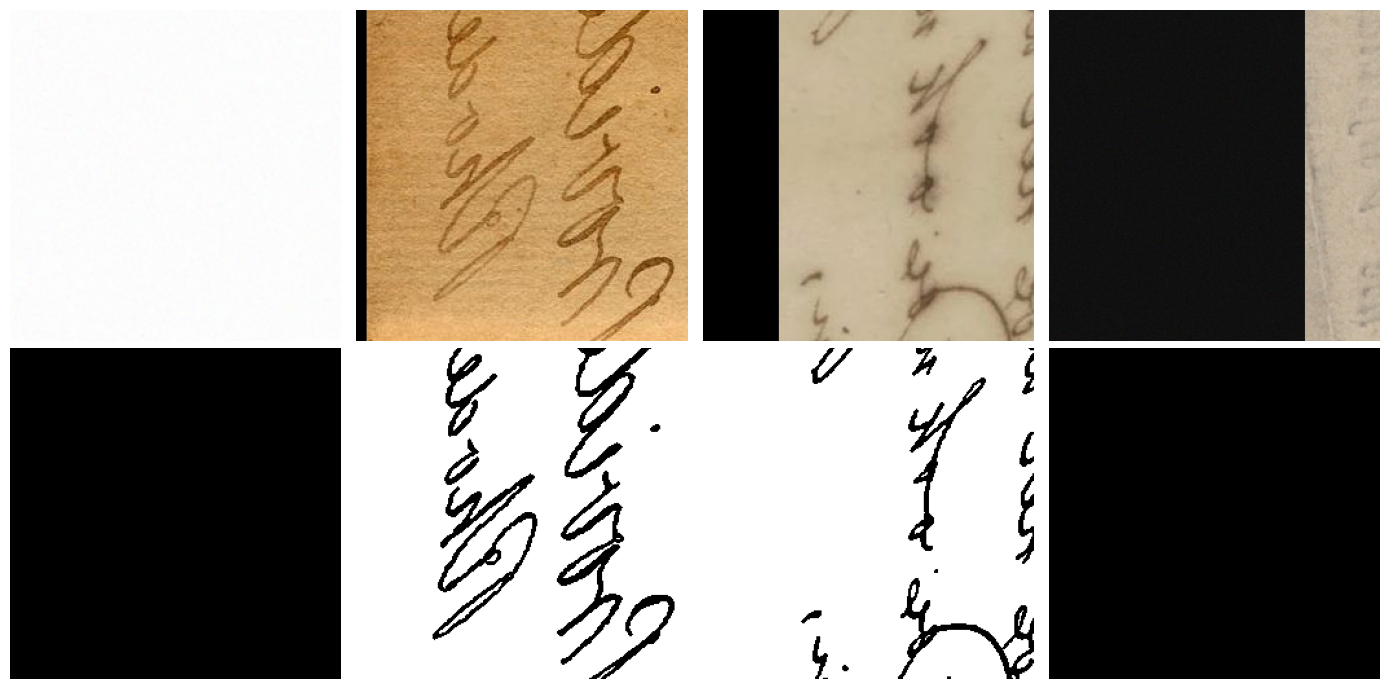

In [13]:
def to_tensors(img, mask):
    x = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))).float() / 255.0
    y = torch.from_numpy(np.ascontiguousarray(mask)).float().unsqueeze(0)
    return x, y

def add_stain(img):
    h, w = img.shape[:2]
    blob = np.zeros((h, w), np.float32)
    for _ in range(random.randint(1, 3)):
        cv2.circle(blob, (random.randint(0, w - 1), random.randint(0, h - 1)), random.randint(h // 8, h // 2), 1.0, -1)
    blob = cv2.GaussianBlur(blob, (0, 0), sigmaX=max(h, w) / 10)
    blob /= blob.max() + 1e-6
    tint = np.array([random.uniform(0.6, 0.95), random.uniform(0.5, 0.85), random.uniform(0.3, 0.7)], np.float32)
    out = img.astype(np.float32) * (1 - blob[..., None] * (1 - tint) * random.uniform(0.3, 1.0))
    return np.clip(out, 0, 255).astype(np.uint8)

def warm_tint(img):                                           # paper yellowing
    k = np.array([1.0, random.uniform(0.88, 0.98), random.uniform(0.65, 0.9)], np.float32)
    return np.clip(img.astype(np.float32) * k, 0, 255).astype(np.uint8)

def augment(img, mask):
    if random.random() < 0.5: img, mask = img[:, ::-1], mask[:, ::-1]
    if random.random() < 0.5: img, mask = img[::-1], mask[::-1]
    k = random.randint(0, 3)
    img, mask = np.rot90(img, k), np.rot90(mask, k)
    img = img.astype(np.float32)
    if random.random() < 0.7:
        img = (img - 128) * random.uniform(0.8, 1.2) + 128 + random.uniform(-25, 25)
    img = np.clip(img, 0, 255).astype(np.uint8)
    if random.random() < 0.3: img = warm_tint(img)
    if random.random() < 0.3: img = add_stain(img)
    if random.random() < 0.3:
        img = np.clip(img + np.random.normal(0, random.uniform(2, 10), img.shape), 0, 255).astype(np.uint8)
    if random.random() < 0.2: img = cv2.GaussianBlur(img, (3, 3), 0)
    return np.ascontiguousarray(img), np.ascontiguousarray(mask)

def pad_to(img, mask, size):
    h, w = mask.shape
    ph, pw = max(0, size - h), max(0, size - w)
    if ph or pw:
        img = np.pad(img, ((0, ph), (0, pw), (0, 0)), mode="edge")
        mask = np.pad(mask, ((0, ph), (0, pw)), mode="edge")
    return img, mask

class TrainPatches(Dataset):
    """Random 256x256 crops from the Restomer train patches; text-containing patches are sampled far more often."""
    def __init__(self, df, n_per_epoch=PATCHES_PER_EPOCH, patch=PATCH, blank_weight=0.1):
        self.imgs, self.gts, self.text = df.image_path.values, df.gt_path.values, df.text.values
        w = np.where(self.text > 0.002, 1.0, blank_weight)
        self.p, self.n, self.patch = w / w.sum(), n_per_epoch, patch
    def __len__(self): return self.n
    def __getitem__(self, k):
        i = np.random.choice(len(self.imgs), p=self.p)
        img = read_img(self.imgs[i]); mask = gt_to_mask(read_img(self.gts[i], gray=True))
        img, mask = pad_to(img, mask, self.patch)
        h, w = mask.shape
        for _ in range(6):                                   # try a few crops, keep one that contains ink
            y, x = random.randint(0, h - self.patch), random.randint(0, w - self.patch)
            if mask[y:y + self.patch, x:x + self.patch].mean() > 0.005 or self.text[i] <= 0.002: break
        return to_tensors(*augment(img[y:y + self.patch, x:x + self.patch], mask[y:y + self.patch, x:x + self.patch]))

class EvalPatches(Dataset):
    def __init__(self, df, patch=PATCH):
        self.imgs, self.gts, self.patch = df.image_path.values, df.gt_path.values, patch
    def __len__(self): return len(self.imgs)
    def __getitem__(self, k):
        img = read_img(self.imgs[k]); mask = gt_to_mask(read_img(self.gts[k], gray=True))
        img, mask = pad_to(img, mask, self.patch)
        return to_tensors(np.ascontiguousarray(img[:self.patch, :self.patch]), np.ascontiguousarray(mask[:self.patch, :self.patch]))

train_loader = DataLoader(TrainPatches(pairs["train"]), batch_size=BATCH, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
val_loader = DataLoader(EvalPatches(pairs["val"]), batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS)
print(f"train patches/epoch: {PATCHES_PER_EPOCH} | val patches: {len(val_loader.dataset)}")

xb, yb = next(iter(train_loader))
print("batch:", xb.shape, yb.shape, "| ink ratio in batch:", round(yb.mean().item(), 3))
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for c in range(4):
    ax[0, c].imshow(xb[c].permute(1, 2, 0)); ax[0, c].axis("off")
    ax[1, c].imshow(1 - yb[c, 0], cmap="gray"); ax[1, c].axis("off")
plt.tight_layout(); plt.show()

### T3: Model, loss, inference and metrics

In [14]:
from skimage.filters import threshold_sauvola

class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.inc = DoubleConv(in_ch, c[0])
        self.d1, self.d2 = DoubleConv(c[0], c[1]), DoubleConv(c[1], c[2])
        self.d3, self.d4 = DoubleConv(c[2], c[3]), DoubleConv(c[3], c[4])
        self.pool = nn.MaxPool2d(2)
        self.u1, self.c1 = nn.ConvTranspose2d(c[4], c[3], 2, stride=2), DoubleConv(c[3] * 2, c[3])
        self.u2, self.c2 = nn.ConvTranspose2d(c[3], c[2], 2, stride=2), DoubleConv(c[2] * 2, c[2])
        self.u3, self.c3 = nn.ConvTranspose2d(c[2], c[1], 2, stride=2), DoubleConv(c[1] * 2, c[1])
        self.u4, self.c4 = nn.ConvTranspose2d(c[1], c[0], 2, stride=2), DoubleConv(c[0] * 2, c[0])
        self.outc = nn.Conv2d(c[0], out_ch, 1)
    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.d1(self.pool(x1)); x3 = self.d2(self.pool(x2))
        x4 = self.d3(self.pool(x3)); x5 = self.d4(self.pool(x4))
        x = self.c1(torch.cat([self.u1(x5), x4], 1))
        x = self.c2(torch.cat([self.u2(x), x3], 1))
        x = self.c3(torch.cat([self.u3(x), x2], 1))
        x = self.c4(torch.cat([self.u4(x), x1], 1))
        return self.outc(x)

class DiceBCELoss(nn.Module):
    def __init__(self, w_bce=0.5, w_dice=0.5, eps=1.0):
        super().__init__()
        self.bce, self.wb, self.wd, self.eps = nn.BCEWithLogitsLoss(), w_bce, w_dice, eps
    def forward(self, logits, target):
        bce = self.bce(logits, target)
        p = torch.sigmoid(logits).flatten(1); t = target.flatten(1)
        dice = 1 - ((2 * (p * t).sum(1) + self.eps) / (p.sum(1) + t.sum(1) + self.eps)).mean()
        return self.wb * bce + self.wd * dice

criterion = DiceBCELoss()
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

def train_one_epoch(model, loader, opt):
    model.train(); total = 0
    for x, y in tqdm(loader, leave=False, desc="train"):
        x, y = x.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        total += loss.item() * x.size(0)
    return total / len(loader.dataset)

@torch.no_grad()
def validate(model, loader):
    model.eval(); total, tp, fp_, fn = 0, 0.0, 0.0, 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(x); total += criterion(logits, y).item() * x.size(0)
        pred = (torch.sigmoid(logits.float()) > 0.5).float()
        tp += (pred * y).sum().item(); fp_ += (pred * (1 - y)).sum().item(); fn += ((1 - pred) * y).sum().item()
    prec, rec = tp / (tp + fp_ + 1e-8), tp / (tp + fn + 1e-8)
    return total / len(loader.dataset), prec, rec, 2 * prec * rec / (prec + rec + 1e-8), tp / (tp + fp_ + fn + 1e-8)

@torch.no_grad()
def predict_full(model, rgb, patch=PATCH, overlap=0.5, bs=8):
    """Text-probability map with the same HxW as the input, using blended sliding windows."""
    model.eval()
    h, w = rgb.shape[:2]
    stride = int(patch * (1 - overlap))
    H, W = max(h, patch), max(w, patch)
    if (H - patch) % stride: H += stride - (H - patch) % stride
    if (W - patch) % stride: W += stride - (W - patch) % stride
    padded = np.pad(rgb, ((0, H - h), (0, W - w), (0, 0)), mode="edge")
    win1d = np.hanning(patch + 2)[1:-1].astype(np.float32)
    win = np.outer(win1d, win1d)
    acc, wsum = np.zeros((H, W), np.float32), np.zeros((H, W), np.float32)
    coords = [(y, x) for y in range(0, H - patch + 1, stride) for x in range(0, W - patch + 1, stride)]
    for i in range(0, len(coords), bs):
        chunk = coords[i:i + bs]
        batch = np.stack([padded[y:y + patch, x:x + patch] for y, x in chunk])
        t = torch.from_numpy(batch).permute(0, 3, 1, 2).float().div(255).to(device)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            p = torch.sigmoid(model(t)).float().cpu().numpy()[:, 0]
        for (y, x), pp in zip(chunk, p):
            acc[y:y + patch, x:x + patch] += pp * win
            wsum[y:y + patch, x:x + patch] += win
    return (acc / np.maximum(wsum, 1e-8))[:h, :w]

def binary_metrics(pred, gt, eps=1e-8):
    pred, gt = pred.astype(bool), gt.astype(bool)
    tp = np.logical_and(pred, gt).sum(); fp_ = np.logical_and(pred, ~gt).sum(); fn = np.logical_and(~pred, gt).sum()
    prec, rec = tp / (tp + fp_ + eps), tp / (tp + fn + eps)
    mse = np.mean(pred != gt)
    return dict(F1=2 * prec * rec / (prec + rec + eps), Precision=prec, Recall=rec, IoU=tp / (tp + fp_ + fn + eps),
                Accuracy=1 - mse, PSNR=10 * np.log10(1.0 / mse) if mse > 0 else 100.0)

def otsu_bin(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    _, b = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU); return b > 0

def sauvola_bin(rgb, window=51, k=0.2):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY); return gray < threshold_sauvola(gray, window_size=window, k=k)

model = UNet(base=BASE_CH).to(device)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}", "| output:", model(torch.randn(2, 3, PATCH, PATCH).to(device)).shape)

Parameters: 7,763,041 | output: torch.Size([2, 1, 256, 256])


### T4: Train

In [15]:
RETRAIN = False        # True: train from scratch and overwrite best_unet_v2.pth | False: reuse the saved model
CKPT = OUT_DIR / "best_unet_v2.pth"

if CKPT.exists() and (OUT_DIR / "history_v2.csv").exists() and not RETRAIN:
    history = pd.read_csv(OUT_DIR / "history_v2.csv").to_dict("list")
    best_f1 = max(history["val_f1"])
    print(f"Reusing saved model: {len(history['train_loss'])} epochs, best val F1 {best_f1:.4f}  (set RETRAIN = True to train again)")
else:
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
    history = dict(train_loss=[], val_loss=[], val_prec=[], val_rec=[], val_f1=[], val_iou=[])
    best_f1, bad_epochs = -1, 0
    print(f"Training: {EPOCHS} epochs x {PATCHES_PER_EPOCH} patches | batch {BATCH} | base channels {BASE_CH} | device {device}")

    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        tr = train_one_epoch(model, train_loader, opt)
        vl, vp, vr, vf, vi = validate(model, val_loader)
        sched.step(vf)
        for k, v in zip(history, [tr, vl, vp, vr, vf, vi]): history[k].append(v)
        flag = ""
        if vf > best_f1:
            best_f1, bad_epochs, flag = vf, 0, " <- best"
            torch.save({"model": model.state_dict(), "base": BASE_CH, "patch": PATCH}, CKPT)
        else:
            bad_epochs += 1
        print(f"Epoch {epoch:02d}/{EPOCHS} | train {tr:.4f} | val {vl:.4f} | P {vp:.3f} R {vr:.3f} F1 {vf:.4f} | "
              f"lr {opt.param_groups[0]['lr']:.1e} | {time.time()-t0:.0f}s{flag}")
        if bad_epochs >= PATIENCE:
            print("Early stopping"); break
    pd.DataFrame(history).to_csv(OUT_DIR / "history_v2.csv", index=False)
    print("Best val F1:", round(best_f1, 4))

Reusing saved model: 20 epochs, best val F1 0.9089  (set RETRAIN = True to train again)


### T5: Training curves

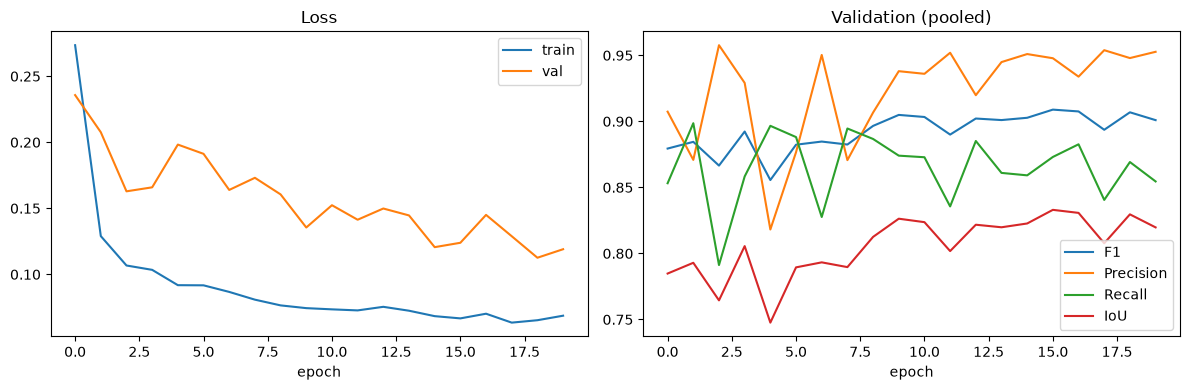

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
for k, lab in [("val_f1", "F1"), ("val_prec", "Precision"), ("val_rec", "Recall"), ("val_iou", "IoU")]:
    ax[1].plot(history[k], label=lab)
ax[1].set_title("Validation (pooled)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves_v2.png", dpi=150); plt.show()

### T6: Test patches (page-disjoint from training)

In [17]:
ck = torch.load(CKPT, map_location=device)
model = UNet(base=ck["base"]).to(device); model.load_state_dict(ck["model"]); model.eval()

def counts(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    return np.array([(pred & gt).sum(), (pred & ~gt).sum(), (~pred & gt).sum(), (~pred & ~gt).sum()], dtype=np.int64)

def from_counts(c):
    tp, fp_, fn, tn = [float(v) for v in c]
    prec, rec = tp / (tp + fp_ + 1e-8), tp / (tp + fn + 1e-8)
    return dict(Precision=prec, Recall=rec, F1=2 * prec * rec / (prec + rec + 1e-8),
                IoU=tp / (tp + fp_ + fn + 1e-8), Accuracy=(tp + tn) / (tp + fp_ + fn + tn))

tot = {m: np.zeros(4, np.int64) for m in ["U-Net", "Sauvola", "Otsu"]}
per = {m: [] for m in tot}                                   # per-patch F1 on patches that contain ink
for r in tqdm(pairs["test"].itertuples(), total=len(pairs["test"]), desc="test patches"):
    rgb = read_img(r.image_path); gt = gt_to_mask(read_img(r.gt_path, gray=True))
    preds = {"U-Net": predict_full(model, rgb) > 0.5, "Sauvola": sauvola_bin(rgb), "Otsu": otsu_bin(rgb)}
    for m, p in preds.items():
        tot[m] += counts(p, gt)
        if gt.sum() > 0: per[m].append(binary_metrics(p, gt)["F1"])

patch_res = pd.DataFrame({m: from_counts(c) for m, c in tot.items()}).T
patch_res["F1_mean_per_patch"] = [float(np.mean(per[m])) for m in patch_res.index]
patch_res = patch_res.round(4).sort_values("F1", ascending=False)
display(patch_res)
patch_res.to_csv(OUT_DIR / "test_patch_results_v2.csv")
print(f"patches with ink: {len(per['U-Net'])} of {len(pairs['test'])} | accuracy is inflated by background, so use F1")

test patches:   0%|          | 0/266 [00:00<?, ?it/s]

,Precision,Recall,F1,IoU,Accuracy,F1_mean_per_patch
U-Net,0.8765,0.8844,0.8804,0.7864,0.9864,0.8361
Sauvola,0.5399,0.7540,0.6292,0.4590,0.9496,0.6859
Otsu,0.1936,0.8907,0.3181,0.1891,0.7833,0.6272


patches with ink: 174 of 266 | accuracy is inflated by background, so use F1


### T7: Full-page test vs Otsu and Sauvola, with bootstrap confidence intervals

In [18]:
rows, PRED = [], {}
for r in tqdm(dibco_test.itertuples(), total=len(dibco_test), desc="test pages"):
    rgb = read_img(r.image_path); gt = gt_to_mask(read_img(r.gt_path, gray=True))
    prob = predict_full(model, rgb); PRED[r.image_path] = prob > 0.5
    for name, p in {"U-Net": prob > 0.5, "Sauvola": sauvola_bin(rgb), "Otsu": otsu_bin(rgb)}.items():
        rows.append(dict(page=f"{r.year}/{Path(r.image_path).name}", year=r.year, method=name, **binary_metrics(p, gt)))

pages_df = pd.DataFrame(rows)
pages_df.to_csv(OUT_DIR / "test_pages_per_page_v2.csv", index=False)
cols = ["F1", "Precision", "Recall", "IoU", "Accuracy", "PSNR"]
page_summary = pages_df.groupby("method")[cols].agg(["mean", "std"]).round(3)
display(page_summary.sort_values(("F1", "mean"), ascending=False))
f1_by_year = pages_df[pages_df.method == "U-Net"].groupby("year").F1.agg(["mean", "count"]).round(3)
print("\nU-Net F1 by contest year (pages):"); display(f1_by_year)
wide = pages_df.pivot(index="page", columns="method", values="F1")
print(f"U-Net beats Sauvola on {int((wide['U-Net'] > wide['Sauvola']).sum())} of {len(wide)} pages, Otsu on {int((wide['U-Net'] > wide['Otsu']).sum())}")

test pages:   0%|          | 0/23 [00:00<?, ?it/s]

F1        Precision        Recall           IoU        Accuracy  \
          mean    std      mean    std   mean    std   mean    std     mean   
method                                                                        
U-Net    0.887  0.086     0.887  0.105  0.897  0.098  0.808  0.133    0.985   
Sauvola  0.682  0.195     0.674  0.245  0.785  0.209  0.548  0.218    0.949   
Otsu     0.571  0.281     0.496  0.323  0.880  0.129  0.453  0.284    0.833   

                  PSNR         
           std    mean    std  
method                         
U-Net    0.013  20.045  4.384  
Sauvola  0.047  14.450  3.912  
Otsu     0.200  11.550  6.706


U-Net F1 by contest year (pages):


,mean,count
year,,
2009,0.850,1
2010,0.977,1
2012,0.980,2
2014,0.981,1
2017,0.922,4
2018,0.869,10
2019,0.815,4


U-Net beats Sauvola on 23 of 23 pages, Otsu on 21


In [19]:
rng_b = np.random.default_rng(SEED)
wide = pages_df.pivot(index="page", columns="method", values="F1")
n, B = len(wide), 5000
idx = rng_b.integers(0, n, size=(B, n))
def ci(v): return np.percentile(v, [2.5, 97.5]).round(3)
for m in ["U-Net", "Sauvola", "Otsu"]:
    means = wide[m].values[idx].mean(1)
    print(f"{m:8s} mean F1 {wide[m].mean():.3f} | 95% CI {ci(means)}")
diff = (wide["U-Net"] - wide["Sauvola"])
print(f"U-Net minus Sauvola: {diff.mean():.3f} | 95% CI {ci(diff.values[idx].mean(1))}")


U-Net    mean F1 0.887 | 95% CI [0.854 0.921]
Sauvola  mean F1 0.682 | 95% CI [0.606 0.761]
Otsu     mean F1 0.571 | 95% CI [0.457 0.684]
U-Net minus Sauvola: 0.205 | 95% CI [0.148 0.267]


### T8: Visual results and error maps

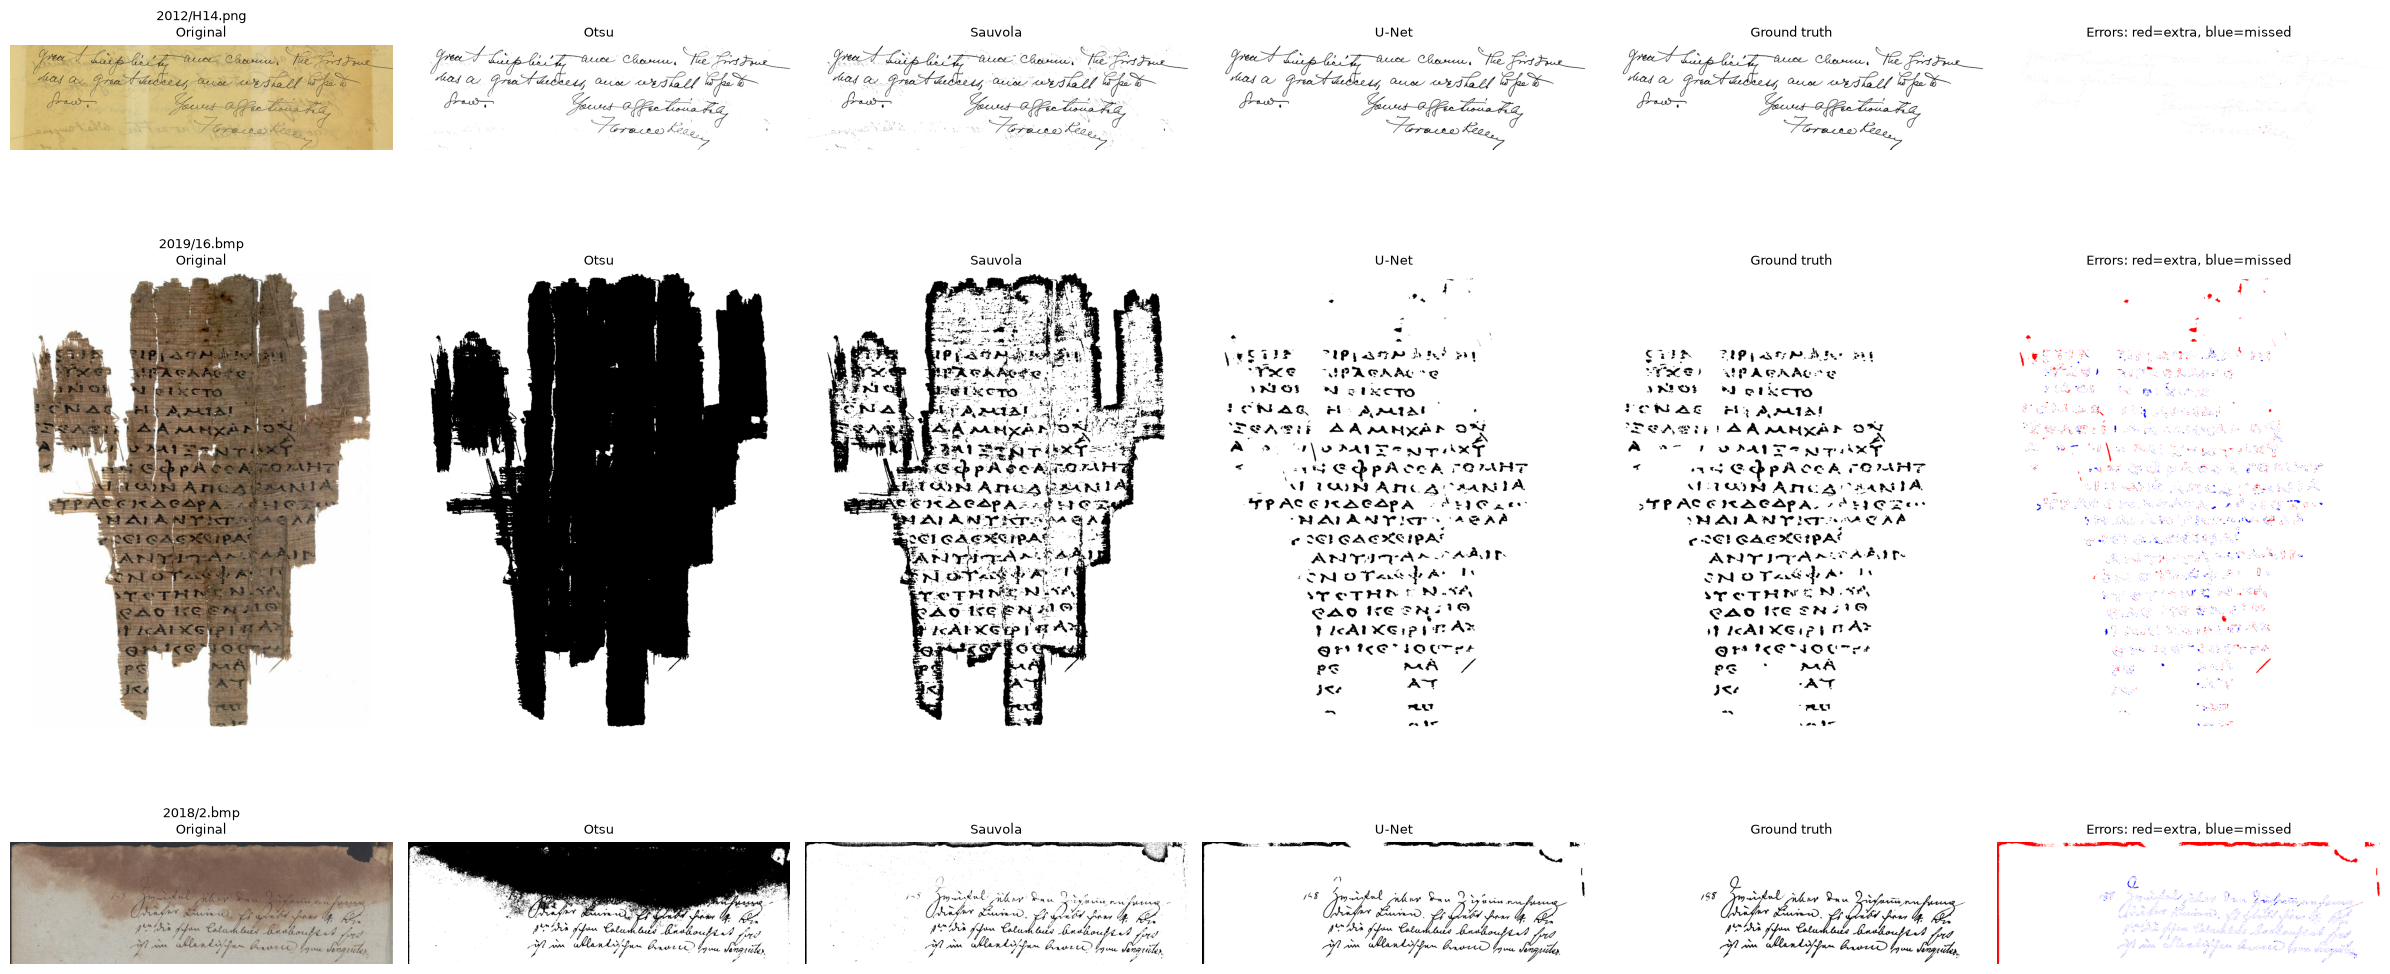

best / median / worst page: 2012/H14.png 2019/16.bmp 2018/2.bmp


In [20]:
def show_compare(pages, fname):
    fig, ax = plt.subplots(len(pages), 6, figsize=(24, 4.3 * len(pages))); ax = np.atleast_2d(ax)
    for r_, pg in enumerate(pages):
        row = dibco_test[[f"{y}/{Path(p).name}" == pg for y, p in zip(dibco_test.year, dibco_test.image_path)]].iloc[0]
        rgb = read_img(row.image_path); gt = gt_to_mask(read_img(row.gt_path, gray=True)).astype(bool); pr = PRED[row.image_path]
        err = np.ones((*gt.shape, 3), np.float32)
        err[pr & ~gt] = [1, 0, 0]; err[~pr & gt] = [0, 0, 1]
        panels = [("Original", rgb), ("Otsu", 1 - otsu_bin(rgb)), ("Sauvola", 1 - sauvola_bin(rgb)),
                  ("U-Net", 1 - pr), ("Ground truth", 1 - gt), ("Errors: red=extra, blue=missed", err)]
        for c, (t, im) in enumerate(panels):
            ax[r_, c].imshow(im, cmap=None if c in (0, 5) else "gray"); ax[r_, c].set_title(f"{pg}\n{t}" if c == 0 else t, fontsize=9); ax[r_, c].axis("off")
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=90); plt.show()

u = pages_df[pages_df.method == "U-Net"].sort_values("F1")
show_compare([u.page.iloc[-1], u.page.iloc[len(u) // 2], u.page.iloc[0]], "compare_best_median_worst_v2.png")
print("best / median / worst page:", u.page.iloc[-1], u.page.iloc[len(u) // 2], u.page.iloc[0])

### T9: OCR on held-out pages (Tesseract)

In [21]:
import pytesseract
from rapidfuzz.distance import Levenshtein
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
print("Tesseract:", pytesseract.get_tesseract_version())
MAX_OCR_PAGES = 24                      # lower this if it takes too long

def ocr(img):
    try: return " ".join(pytesseract.image_to_string(img, lang="eng", timeout=90).split())
    except Exception: return ""
def cer(h, r): return Levenshtein.distance(h, r) / max(len(r), 1)
def wer(h, r):
    h, r = h.split(), r.split(); return Levenshtein.distance(h, r) / max(len(r), 1)
def doc_type(n): n = n.upper(); return "printed" if n.startswith("P") else "handwritten" if n.startswith("H") else "mixed"

cand = fp.copy(); cand["type"] = [doc_type(Path(p).name) for p in cand.image_path]
sel = pd.concat([cand[cand.type == "printed"], cand[cand.type != "printed"].sample(frac=1, random_state=SEED)]).head(MAX_OCR_PAGES)
print("pages selected:", len(sel), "| printed:", int((sel.type == "printed").sum()))

rows = []
for r in tqdm(sel.itertuples(), total=len(sel), desc="OCR"):
    gt = gt_to_mask(read_img(r.gt_path, gray=True))
    ref = ocr(((1 - gt) * 255).astype(np.uint8))
    if len(ref.split()) < 10: continue                      # no usable reference text on this page
    rgb = read_img(r.image_path)
    pr = PRED[r.image_path] if r.image_path in PRED else predict_full(model, rgb) > 0.5
    raw = ocr(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY))
    unet = ocr(((~pr) * 255).astype(np.uint8))
    sau = ocr(((~sauvola_bin(rgb)) * 255).astype(np.uint8))
    rows.append(dict(page=f"{r.year}/{Path(r.image_path).name}", split=r.split, type=r.type, words_ref=len(ref.split()),
                     CER_original=cer(raw, ref), CER_sauvola=cer(sau, ref), CER_unet=cer(unet, ref),
                     WER_original=wer(raw, ref), WER_sauvola=wer(sau, ref), WER_unet=wer(unet, ref)))

ocr_df = pd.DataFrame(rows).round(3)
ocr_df.to_csv(OUT_DIR / "ocr_results_v2.csv", index=False)
display(ocr_df)
m = ["CER_original", "CER_sauvola", "CER_unet", "WER_original", "WER_sauvola", "WER_unet"]
print(f"pages with usable text: {len(ocr_df)}"); display(ocr_df.groupby("type")[m].mean().round(3))
print("overall mean:"); display(ocr_df[m].mean().round(3).to_frame().T)

Tesseract: 5.5.3.20260724
pages selected: 24 | printed: 5


OCR:   0%|          | 0/24 [00:00<?, ?it/s]

,page,split,type,words_ref,CER_original,CER_sauvola,CER_unet,WER_original,WER_sauvola,WER_unet
0,2009/P03.bmp,val,printed,12,0.340,0.381,0.216,0.833,1.083,0.583
1,2011/PR4.png,val,printed,24,0.119,0.257,0.040,0.542,0.958,0.250
2,2011/PR6.png,val,printed,12,0.448,0.989,0.011,0.750,1.000,0.083
3,2013/PR01.bmp,val,printed,56,0.168,0.145,0.055,0.589,0.429,0.286
4,2013/PR03.bmp,val,printed,22,0.019,0.031,0.031,0.136,0.227,0.182
5,2016/9.bmp,val,mixed,10,1.244,1.422,0.689,1.700,1.800,1.100
6,2013/HW01.bmp,val,handwritten,50,1.013,1.197,0.699,1.840,2.100,1.240
7,2017/19.bmp,val,mixed,61,0.952,0.283,0.061,1.377,0.738,0.279
8,2014/H08.png,test,handwritten,30,0.472,0.429,0.307,0.867,0.867,0.800
9,2017/4.bmp,test,mixed,37,0.809,2.426,0.652,1.000,3.054,0.946


pages with usable text: 14


,CER_original,CER_sauvola,CER_unet,WER_original,WER_sauvola,WER_unet
type,,,,,,
handwritten,0.742,0.813,0.503,1.354,1.484,1.020
mixed,1.598,1.895,1.041,1.745,2.637,1.393
printed,0.219,0.361,0.071,0.570,0.739,0.277


overall mean:


,CER_original,CER_sauvola,CER_unet,WER_original,WER_sauvola,WER_unet
0,0.983,1.192,0.617,1.269,1.794,0.941


In [22]:
m = ["CER_original", "CER_sauvola", "CER_unet", "WER_original", "WER_sauvola", "WER_unet"]
print("median:"); display(ocr_df[m].median().round(3).to_frame().T)
for k in ["CER", "WER"]:
    b = int((ocr_df[f"{k}_unet"] < ocr_df[f"{k}_original"]).sum())
    print(f"{k}: U-Net better than the original image on {b} of {len(ocr_df)} pages")


median:


,CER_original,CER_sauvola,CER_unet,WER_original,WER_sauvola,WER_unet
0,0.46,0.614,0.268,0.934,1.042,0.692


CER: U-Net better than the original image on 10 of 14 pages
WER: U-Net better than the original image on 10 of 14 pages


### T10: Save and summarize

In [23]:
torch.save(model.state_dict(), OUT_DIR / "unet_v2_weights_only.pth")
with open(OUT_DIR / "config_v2.json", "w") as f:
    json.dump(dict(patch=PATCH, base_ch=BASE_CH, epochs_run=len(history["train_loss"]), best_val_f1=float(best_f1), lr=LR,
                   batch=BATCH, patches_per_epoch=PATCHES_PER_EPOCH, seed=SEED, train_patches=len(pairs["train"]),
                   val_patches=len(pairs["val"]), test_patches=len(pairs["test"]), test_pages=len(dibco_test),
                   val_pages=len(dibco_val)), f, indent=2)

u = pages_df[pages_df.method == "U-Net"]
print("=" * 64); print("PROJECT SUMMARY - U-Net document binarization (v2)"); print("=" * 64)
print(f"Data: {len(pairs['train'])} train / {len(pairs['val'])} val / {len(pairs['test'])} test patches | {len(dibco_test)} held-out test pages")
print(f"Test patches (pooled)   U-Net F1 {patch_res.loc['U-Net','F1']:.3f} | P {patch_res.loc['U-Net','Precision']:.3f} | R {patch_res.loc['U-Net','Recall']:.3f}")
print(f"Test pages (mean +- sd) U-Net F1 {u.F1.mean():.3f} +- {u.F1.std():.3f} | best baseline: "
      f"{pages_df[pages_df.method != 'U-Net'].groupby('method').F1.mean().idxmax()} {pages_df[pages_df.method != 'U-Net'].groupby('method').F1.mean().max():.3f}")
if len(ocr_df): print(f"OCR median CER original -> U-Net: {ocr_df.CER_original.median():.3f} -> {ocr_df.CER_unet.median():.3f}")
print("\nLimitations: small benchmark, split partly by contest year, handwritten OCR remains weak.")

PROJECT SUMMARY - U-Net document binarization (v2)
Data: 6859 train / 239 val / 266 test patches | 23 held-out test pages
Test patches (pooled)   U-Net F1 0.880 | P 0.876 | R 0.884
Test pages (mean +- sd) U-Net F1 0.887 +- 0.086 | best baseline: Sauvola 0.682
OCR median CER original -> U-Net: 0.460 -> 0.268

Limitations: small benchmark, split partly by contest year, handwritten OCR remains weak.
